# StreamFlix Content Analytics
## Phase 2 — Exploratory Data Analysis (EDA)

**Analyst:** Kajal Rajak  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook

### Project Overview
This phase explores StreamFlix viewing activity, content performance, subscriber characteristics, and customer feedback using the cleaned datasets prepared in Phase 1.

The analysis focuses on monthly viewing trends, genre performance, content types, geographical distribution, subscriber plans, device usage, age distribution, completion rates, and review sentiment.

### Objective
To create the 10 charts specified in the Project PRD, identify meaningful patterns, document observations, and save the charts as PNG files for reporting and dashboard development.

## Step 1 — Import Libraries

In [17]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## Step 2 — Set Input and Output Paths

In [18]:
DATA_DIR = Path("streamflix_cleaned_data")
CHART_DIR = Path("charts")

CHART_DIR.mkdir(parents=True, exist_ok=True)

table_files = {
    "subscribers": "subscribers_cleaned.csv",
    "titles": "titles_cleaned.csv",
    "watch_history": "watch_history_cleaned.csv",
    "ratings": "ratings_cleaned.csv",
    "reviews": "reviews_cleaned.csv",
    "watchlist": "watchlist_cleaned.csv"
}

missing_files = [
    filename
    for filename in table_files.values()
    if not (DATA_DIR / filename).exists()
]

if missing_files:
    raise FileNotFoundError(
        f"Missing cleaned files: {missing_files}. "
        "Run Phase 1 first and check the DATA_DIR path."
    )

print("Input folder:", DATA_DIR.resolve())
print("Chart output folder:", CHART_DIR.resolve())

Input folder: C:\Users\91916\OneDrive\문서\Jupyter_Notebook\Streamflix-Content-Analytics-Project\streamflix_cleaned_data
Chart output folder: C:\Users\91916\OneDrive\문서\Jupyter_Notebook\Streamflix-Content-Analytics-Project\charts


## Step 3 — Load the Cleaned Datasets

In [19]:
cleaned_data_dict = {
    table_name: pd.read_csv(DATA_DIR / filename)
    for table_name, filename in table_files.items()
}

subscribers = cleaned_data_dict["subscribers"].copy()
titles = cleaned_data_dict["titles"].copy()
watch_history = cleaned_data_dict["watch_history"].copy()
ratings = cleaned_data_dict["ratings"].copy()
reviews = cleaned_data_dict["reviews"].copy()
watchlist = cleaned_data_dict["watchlist"].copy()

for table_name, df in cleaned_data_dict.items():
    print(
        f"{table_name}: "
        f"{df.shape[0]:,} rows × {df.shape[1]} columns"
    )

subscribers: 15,000 rows × 14 columns
titles: 9,000 rows × 21 columns
watch_history: 650,000 rows × 10 columns
ratings: 130,000 rows × 5 columns
reviews: 110,000 rows × 7 columns
watchlist: 65,000 rows × 5 columns


## Step 4 — Prepare Data for Analysis

In [20]:
# Convert date columns to datetime.

date_columns = {
    "subscribers": ["signup_date", "churn_date"],
    "titles": ["date_added", "license_expiry"],
    "watch_history": ["watch_date"],
    "ratings": ["rating_date"],
    "reviews": ["review_date"],
    "watchlist": ["added_date"]
}

for table_name, columns in date_columns.items():
    df = cleaned_data_dict[table_name]

    for col in columns:
        if col in df.columns:
            df[col] = pd.to_datetime(df[col], errors="coerce")


# Refresh dataframe references after date conversion.

subscribers = cleaned_data_dict["subscribers"]
titles = cleaned_data_dict["titles"]
watch_history = cleaned_data_dict["watch_history"]
ratings = cleaned_data_dict["ratings"]
reviews = cleaned_data_dict["reviews"]
watchlist = cleaned_data_dict["watchlist"]


# Convert numeric columns used in the analysis.

for df, columns in [
    (watch_history, ["watch_duration_min", "completion_pct"]),
    (subscribers, ["age", "monthly_price_usd"]),
    (ratings, ["rating"]),
    (titles, ["license_cost_usd"])
]:
    for col in columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")


# Convert viewing duration from minutes to hours.

watch_history["watch_hours"] = (watch_history["watch_duration_min"] / 60)

# Join viewing sessions with title information.

watch_analysis = watch_history.merge(
    titles[
        [
            "title_id",
            "title_name",
            "type",
            "primary_genre",
            "is_original",
            "license_cost_usd"
        ]
    ],
    on="title_id",
    how="left",
    validate="many_to_one"
)

# Join subscriber information.

subscriber_info = subscribers[
    [
        "subscriber_id",
        "country",
        "age",
        "plan_type",
        "is_active"
    ]
].rename(
    columns={
        "country": "subscriber_country",
        "age": "subscriber_age",
        "plan_type": "subscriber_plan",
        "is_active": "subscriber_is_active"
    }
)

watch_analysis = watch_analysis.merge(
    subscriber_info,
    on="subscriber_id",
    how="left",
    validate="many_to_one"
)

# Create month and year fields for time-based analysis.

watch_history["watch_month"] = (
    watch_history["watch_date"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

watch_analysis["watch_month"] = (
    watch_analysis["watch_date"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

watch_analysis["watch_year"] = (
    watch_analysis["watch_date"].dt.year
)

print("Analysis datasets prepared successfully.")

print(f"Viewing sessions: {len(watch_history):,}")
print(f"Analysis records after joins: {len(watch_analysis):,}")

Analysis datasets prepared successfully.
Viewing sessions: 650,000
Analysis records after joins: 650,000


## Step 5 — Monthly Viewing Volume

**PRD requirement**: Create a bar or line chart showing the number of viewing sessions per month across the timeline. Highlight the busiest month.

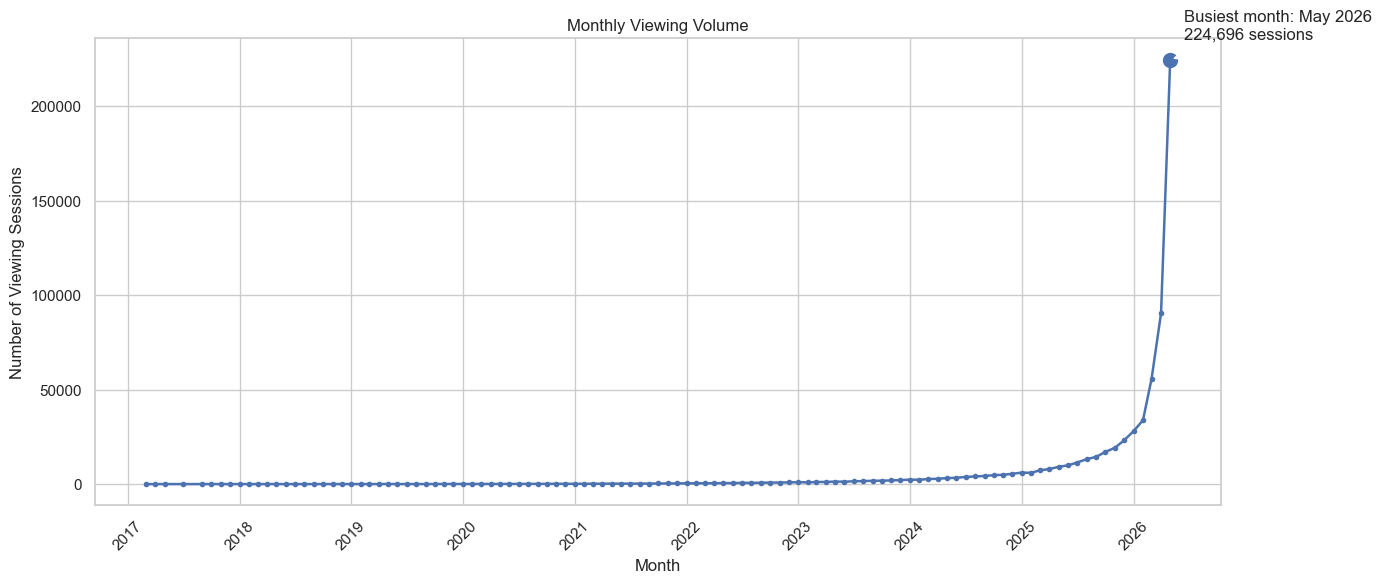

The busiest month was May 2026, with 224,696 viewing sessions.


In [21]:
monthly_sessions = (
    watch_history
    .dropna(subset=["watch_date"])
    .groupby("watch_month", as_index=False)
    .agg(
        total_sessions=("watch_id", "count")
    )
    .sort_values("watch_month")
)

busiest_month = monthly_sessions.loc[
    monthly_sessions["total_sessions"].idxmax()
]

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    monthly_sessions["watch_month"],
    monthly_sessions["total_sessions"],
    marker="o",
    markersize=3,
    linewidth=1.8
)

ax.scatter(
    busiest_month["watch_month"],
    busiest_month["total_sessions"],
    s=100,
    zorder=3
)

ax.annotate(
    f"Busiest month: {busiest_month['watch_month']:%b %Y}\n"
    f"{busiest_month['total_sessions']:,} sessions",
    xy=(
        busiest_month["watch_month"],
        busiest_month["total_sessions"]
    ),
    xytext=(10, 15),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->"}
)

ax.set_title("Monthly Viewing Volume")
ax.set_xlabel("Month")
ax.set_ylabel("Number of Viewing Sessions")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    CHART_DIR / "01_Monthly_Viewing_Volume.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"The busiest month was {busiest_month['watch_month']:%B %Y}, "
    f"with {busiest_month['total_sessions']:,} viewing sessions."
)

**Observation:** May 2026 recorded the highest viewing activity, with 224,696 viewing sessions. The chart shows a gradual increase in viewing volume over the earlier years, followed by a sharp acceleration during late 2025 and early 2026. The unusually large increase in the latest months should be investigated further to determine whether it reflects genuine growth in viewing activity or an underlying data pattern that requires validation.

## Step 6 — Monthly Watch Hours Trend

**PRD requirement:** Convert viewing duration into hours, display the monthly trend, and compare year-over-year performance.

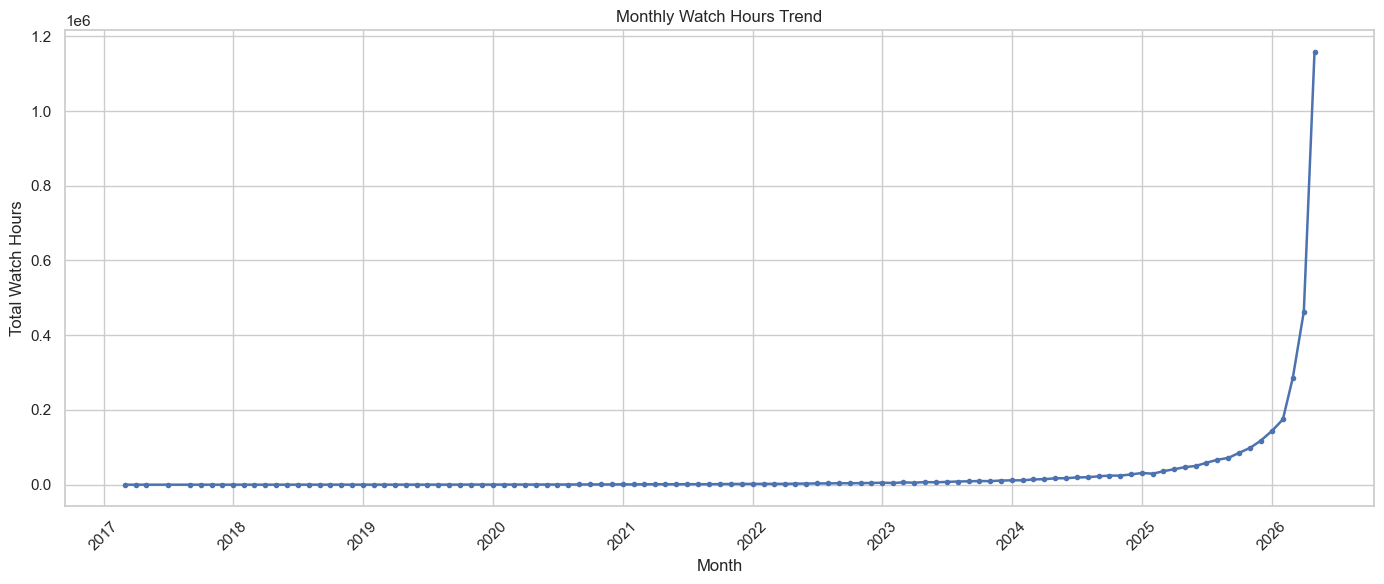

In [22]:
monthly_watch_hours = (
    watch_history
    .dropna(subset=["watch_date"])
    .groupby("watch_month", as_index=False)
    .agg(
        total_watch_hours=("watch_hours", "sum")
    )
    .sort_values("watch_month")
)

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    monthly_watch_hours["watch_month"],
    monthly_watch_hours["total_watch_hours"],
    linewidth=1.8,
    marker="o",
    markersize=3
)

ax.set_title("Monthly Watch Hours Trend")
ax.set_xlabel("Month")
ax.set_ylabel("Total Watch Hours")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    CHART_DIR / "02_Monthly_Watch_Hours_Trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Observation:** Total watch hours increase over time, with a particularly sharp rise during the final months of the timeline. May 2026 recorded approximately 1.16 million watch hours, compared with approximately 463,337 hours in April 2026. This substantial month-to-month increase is a key finding, but it should be validated before concluding that audience engagement has grown at this rate.

## Year-over-year comparison

The dataset extends through June 2026, so 2026 may be an incomplete year. To avoid comparing partial-year totals against complete years, the following calculation uses years with all 12 calendar months.

In [23]:
yearly_watch_hours = (
    watch_history
    .dropna(subset=["watch_date"])
    .assign(
        watch_year=lambda df: df["watch_date"].dt.year
    )
    .groupby("watch_year")
    .agg(
        total_watch_hours=("watch_hours", "sum"),
        months_available=("watch_date", lambda x: x.dt.month.nunique())
    )
    .reset_index()
)

full_years = yearly_watch_hours[
    yearly_watch_hours["months_available"] == 12
].copy()

full_years["yoy_change_pct"] = (
    full_years["total_watch_hours"].pct_change() * 100
)

display(full_years.round(2))

,watch_year,total_watch_hours,months_available,yoy_change_pct
1,2018,583.54,12,NaN
2,2019,1679.41,12,187.80
3,2020,5471.78,12,225.81
4,2021,15435.33,12,182.09
5,2022,37353.96,12,142.00
6,2023,89665.82,12,140.04
7,2024,223994.05,12,149.81
8,2025,733939.06,12,227.66


**Observation:** Annual watch hours increased consistently across the complete years shown, from approximately 584 hours in 2018 to 733,939 hours in 2025. The largest year-over-year growth among these years occurred in 2025, at approximately 227.66% compared with 2024. The 2026 figures are excluded from the annual comparison because the available data does not cover a complete calendar year.

## Step 7 — Genre-wise Watch-Hours Share

**PRD requirement:** Create a pie chart or horizontal bar chart showing watch hours by genre. Identify the genre that earns the most watch time.

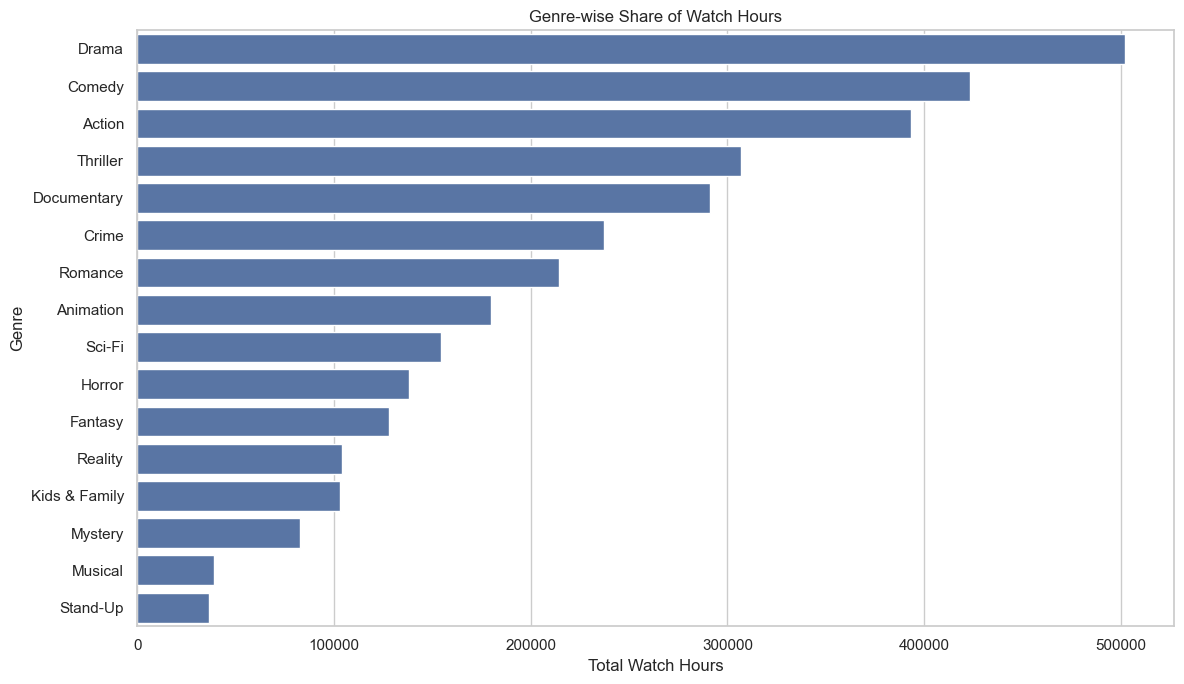

,primary_genre,total_watch_hours,share_pct
5,Drama,501884.47,15.06
2,Comedy,423149.05,12.69
0,Action,393171.92,11.79
15,Thriller,307024.66,9.21
4,Documentary,291216.90,8.74
3,Crime,237435.84,7.12
12,Romance,214332.30,6.43
1,Animation,180093.94,5.40
13,Sci-Fi,154332.21,4.63
7,Horror,138033.61,4.14


In [24]:
genre_watch_hours = (
    watch_analysis
    .dropna(subset=["primary_genre"])
    .groupby("primary_genre", as_index=False)
    .agg(
        total_watch_hours=("watch_hours", "sum")
    )
    .sort_values("total_watch_hours", ascending=False)
)

genre_watch_hours["share_pct"] = (
    genre_watch_hours["total_watch_hours"]
    / genre_watch_hours["total_watch_hours"].sum()
    * 100
)

fig, ax = plt.subplots(figsize=(12, 7))

sns.barplot(
    data=genre_watch_hours,
    y="primary_genre",
    x="total_watch_hours",
    ax=ax
)

ax.set_title("Genre-wise Share of Watch Hours")
ax.set_xlabel("Total Watch Hours")
ax.set_ylabel("Genre")

plt.tight_layout()

plt.savefig(
    CHART_DIR / "03_Genre_Watch_Hours_Share.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(
    genre_watch_hours[
        ["primary_genre", "total_watch_hours", "share_pct"]
    ].round(2)
)

**Observation:** Drama generated the highest watch time, accounting for approximately 15.06% of total watch hours, followed by Comedy at 12.69% and Action at 11.79%. Musical and Stand-Up recorded the lowest shares, at approximately 1.17% and 1.09%, respectively. The results indicate that viewing activity is distributed across several genres, although Drama has the largest share.

## Step 9 — Content Type Split: Movies vs. TV Shows

**PRD requirement:** Create a donut chart showing the share of viewing hours for Movies and TV Shows.

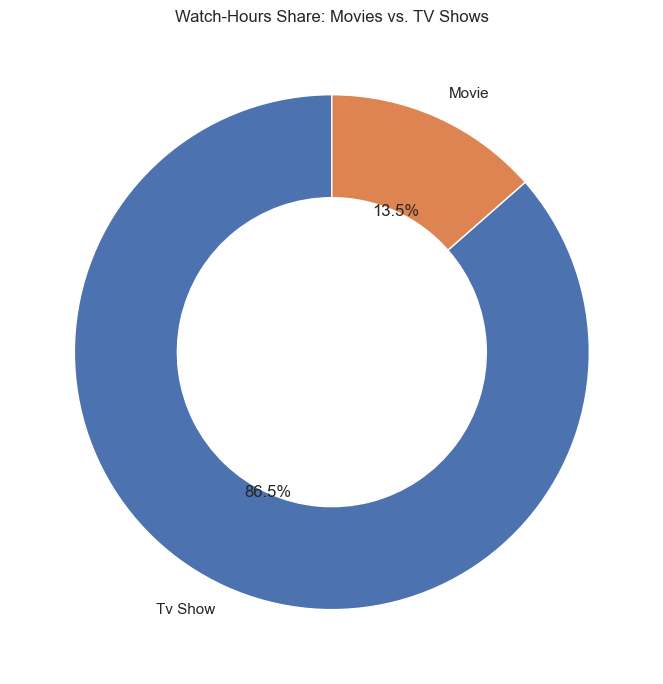

,type,total_watch_hours,share_pct
1,Tv Show,2882608.92,86.47
0,Movie,450858.81,13.53


In [25]:
content_type_hours = (
    watch_analysis
    .dropna(subset=["type"])
    .groupby("type", as_index=False)
    .agg(
        total_watch_hours=("watch_hours", "sum")
    )
    .sort_values("total_watch_hours", ascending=False)
)

content_type_hours["share_pct"] = (
    content_type_hours["total_watch_hours"]
    / content_type_hours["total_watch_hours"].sum()
    * 100
)

fig, ax = plt.subplots(figsize=(8, 7))

ax.pie(
    content_type_hours["total_watch_hours"],
    labels=content_type_hours["type"],
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4, "edgecolor": "white"}
)

ax.set_title("Watch-Hours Share: Movies vs. TV Shows")

plt.tight_layout()

plt.savefig(
    CHART_DIR / "04_Content_Type_Split.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(content_type_hours.round(2))

**Observation:** TV Shows accounted for approximately 86.47% of total watch hours, while Movies contributed 13.53%. This indicates that most recorded viewing time is associated with episodic content rather than movies. The difference is substantial, with TV Shows generating more than six times the watch hours recorded for Movies.

## Step 9 — Top 10 Countries by Watch Hours

**PRD requirement:** Create a horizontal bar chart ranking the top 10 countries by watch hours.

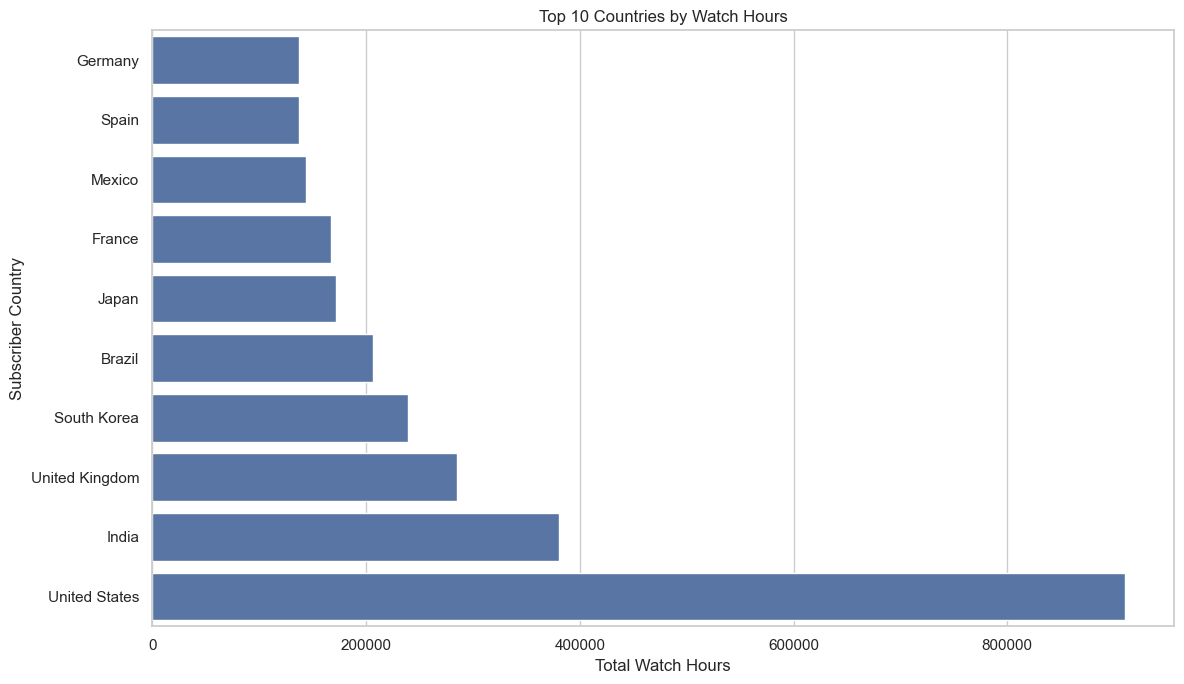

,subscriber_country,total_watch_hours
19,United States,910551.20
7,India,380917.68
18,United Kingdom,285346.35
13,South Korea,239498.93
2,Brazil,206648.20
10,Japan,171707.98
5,France,167418.19
11,Mexico,143971.79
14,Spain,137107.41
6,Germany,136936.38


In [26]:
country_watch_hours = (
    watch_analysis
    .dropna(subset=["subscriber_country"])
    .groupby("subscriber_country", as_index=False)
    .agg(
        total_watch_hours=("watch_hours", "sum")
    )
    .sort_values("total_watch_hours", ascending=False)
    .head(10)
)

country_watch_hours = country_watch_hours.sort_values(
    "total_watch_hours",
    ascending=True
)

fig, ax = plt.subplots(figsize=(12, 7))

sns.barplot(
    data=country_watch_hours,
    y="subscriber_country",
    x="total_watch_hours",
    ax=ax
)

ax.set_title("Top 10 Countries by Watch Hours")
ax.set_xlabel("Total Watch Hours")
ax.set_ylabel("Subscriber Country")

plt.tight_layout()

plt.savefig(
    CHART_DIR / "05_Top_10_Countries_by_Watch_Hours.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(
    country_watch_hours.sort_values(
        "total_watch_hours",
        ascending=False
    ).round(2)
)

**Observation:** The United States ranked first, with approximately 910,551 watch hours, followed by India with 380,918 hours and the United Kingdom with 285,346 hours. The United States contributed substantially more viewing time than any other country in the top 10. These figures are grouped by subscriber country, so they represent viewing activity associated with subscribers in each country rather than the countries where the content was produced.

## Step 10 — Subscriber Plan Distribution

**PRD requirement:** Create a pie chart showing the distribution of Basic with Ads, Standard, and Premium subscribers.

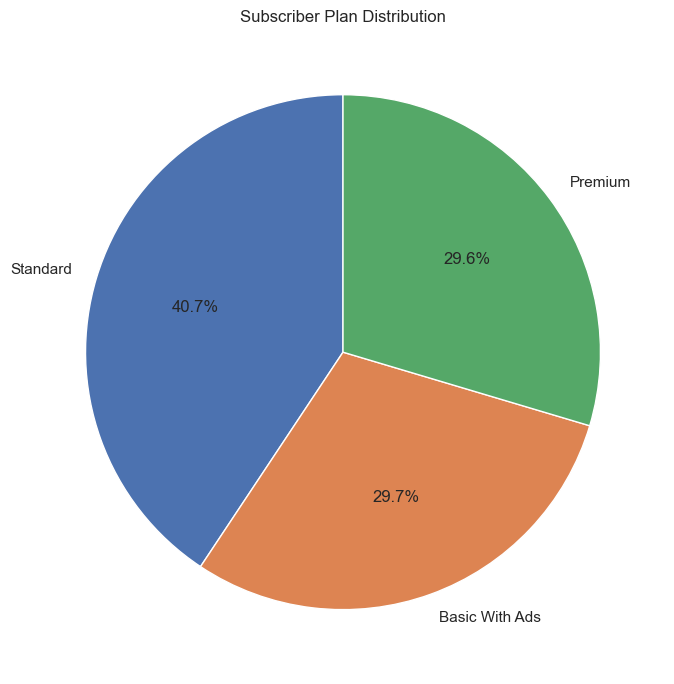

,plan_type,subscriber_count,share_pct
0,Standard,6100,40.666667
1,Basic With Ads,4458,29.720000
2,Premium,4442,29.613333


In [27]:
plan_distribution = (
    subscribers["plan_type"]
    .value_counts()
    .rename_axis("plan_type")
    .reset_index(name="subscriber_count")
)

plan_distribution["share_pct"] = (
    plan_distribution["subscriber_count"]
    / plan_distribution["subscriber_count"].sum()
    * 100
)

fig, ax = plt.subplots(figsize=(9, 7))

ax.pie(
    plan_distribution["subscriber_count"],
    labels=plan_distribution["plan_type"],
    autopct="%1.1f%%",
    startangle=90
)

ax.set_title("Subscriber Plan Distribution")

plt.tight_layout()

plt.savefig(
    CHART_DIR / "06_Subscriber_Plan_Distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(plan_distribution)

**Observation:** The Standard plan had the largest subscriber base, with 6,100 subscribers (40.67%). Basic With Ads accounted for 4,458 subscribers (29.72%), while Premium accounted for 4,442 subscribers (29.61%). The three plans have reasonably balanced distributions overall, although Standard is the most common subscription plan.

## Step 11 — Device Usage

**PRD requirement:** Create a bar chart showing which devices are used most for viewing sessions.

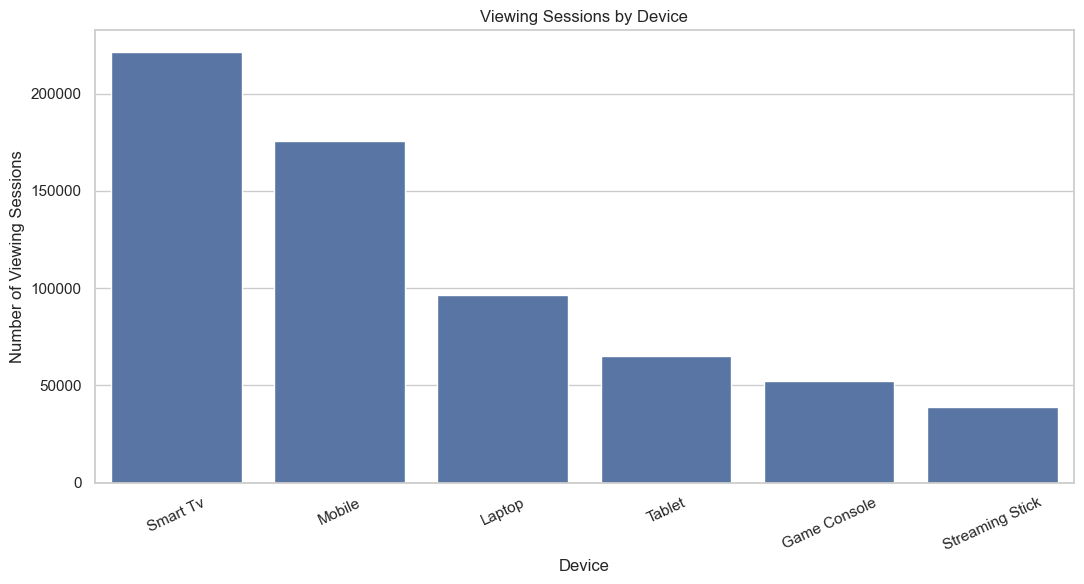

,device,session_count
0,Smart Tv,221446
1,Mobile,175605
2,Laptop,96408
3,Tablet,65276
4,Game Console,52322
5,Streaming Stick,38943


In [28]:
device_usage = (
    watch_history["device"]
    .value_counts()
    .rename_axis("device")
    .reset_index(name="session_count")
    .sort_values("session_count", ascending=False)
)

fig, ax = plt.subplots(figsize=(11, 6))

sns.barplot(
    data=device_usage,
    x="device",
    y="session_count",
    ax=ax
)

ax.set_title("Viewing Sessions by Device")
ax.set_xlabel("Device")
ax.set_ylabel("Number of Viewing Sessions")

plt.xticks(rotation=25)
plt.tight_layout()

plt.savefig(
    CHART_DIR / "07_Device_Usage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(device_usage)

**Observation:** Smart TVs were the most frequently used devices, accounting for 221,446 viewing sessions, followed by Mobile devices with 175,605 sessions. Laptops ranked third with 96,408 sessions, while Streaming Sticks recorded the fewest sessions, at 38,943. The results show that Smart TVs and Mobile devices are the leading viewing platforms in the dataset.

## Step 12 — Subscriber Age Distribution

**PRD requirement:** Create a histogram of subscriber ages and identify which age group watches the most.

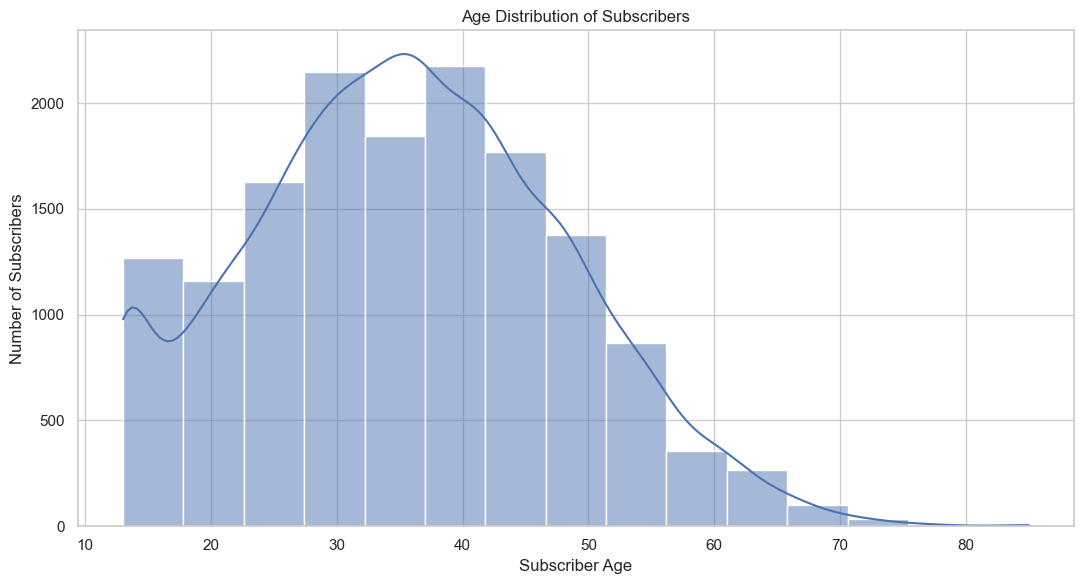

In [29]:
fig, ax = plt.subplots(figsize=(11, 6))

sns.histplot(
    data=subscribers,
    x="age",
    bins=15,
    kde=True,
    ax=ax
)

ax.set_title("Age Distribution of Subscribers")
ax.set_xlabel("Subscriber Age")
ax.set_ylabel("Number of Subscribers")

plt.tight_layout()

plt.savefig(
    CHART_DIR / "08_Subscriber_Age_Distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Age-group watch hours

In [30]:
age_bins = [0, 18, 25, 35, 45, 55, 65, 101]

age_labels = [
    "Under 18",
    "18–24",
    "25–34",
    "35–44",
    "45–54",
    "55–64",
    "65+"
]

watch_analysis["age_group"] = pd.cut(
    watch_analysis["subscriber_age"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

age_group_hours = (
    watch_analysis
    .dropna(subset=["age_group"])
    .groupby("age_group", observed=False, as_index=False)
    .agg(
        total_watch_hours=("watch_hours", "sum")
    )
    .sort_values("total_watch_hours", ascending=False)
)

display(age_group_hours.round(2))

,age_group,total_watch_hours
3,35–44,972656.51
2,25–34,890783.30
4,45–54,603302.27
1,18–24,358171.96
0,Under 18,281924.24
5,55–64,192413.08
6,65+,34216.38


**Observation:** The histogram shows that subscriber ages are concentrated mainly between approximately 25 and 45 years, with the distribution centred around the mid-30s. The mean subscriber age is approximately 35.6 years, and the median is 35 years. There is also a noticeable concentration at age 13, which may warrant checking against the source data to confirm that the unusually high count is expected.

## Step 13 — Completion Rate by Genre

**PRD requirement:** Create a bar chart comparing average completion percentage across genres to identify which genres tend to be finished.

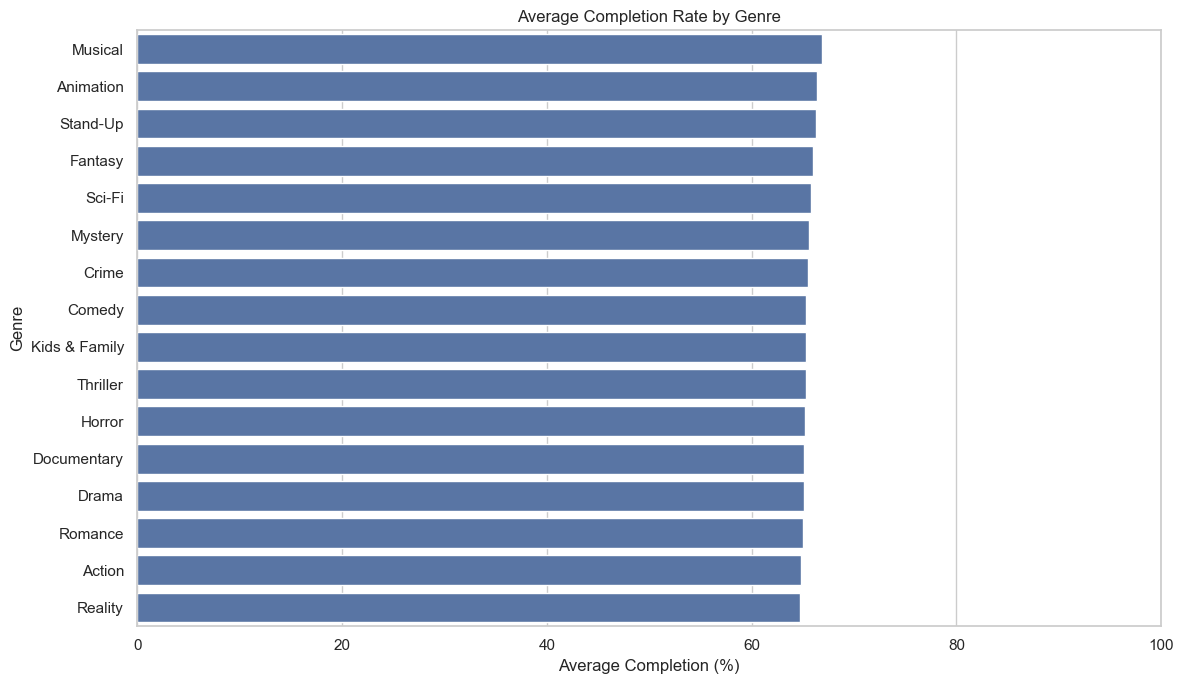

,primary_genre,average_completion_pct,session_count
9,Musical,66.83,7425
1,Animation,66.38,29208
14,Stand-Up,66.32,7993
6,Fantasy,65.97,26407
13,Sci-Fi,65.79,33157
10,Mystery,65.56,18074
3,Crime,65.46,44153
2,Comedy,65.32,84455
8,Kids & Family,65.31,18338
15,Thriller,65.31,58589


In [31]:
completion_by_genre = (
    watch_analysis
    .dropna(subset=["primary_genre", "completion_pct"])
    .groupby("primary_genre", as_index=False)
    .agg(
        average_completion_pct=("completion_pct", "mean"),
        session_count=("watch_id", "count")
    )
    .sort_values("average_completion_pct", ascending=False)
)

fig, ax = plt.subplots(figsize=(12, 7))

sns.barplot(
    data=completion_by_genre,
    y="primary_genre",
    x="average_completion_pct",
    ax=ax
)

ax.set_title("Average Completion Rate by Genre")
ax.set_xlabel("Average Completion (%)")
ax.set_ylabel("Genre")
ax.set_xlim(0, 100)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "09_Completion_Rate_by_Genre.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(completion_by_genre.round(2))

**Observation:** Musical recorded the highest average completion rate at 66.83%, followed closely by Animation at 66.38% and Stand-Up at 66.32%. Reality recorded the lowest average completion rate, at 64.70%. However, the difference between the highest and lowest genres is relatively small, suggesting that average completion rates are broadly similar across genres.

## Step 14 — Review Sentiment Breakdown

**PRD requirement:** Create a bar chart showing the counts of Positive, Neutral, and Negative reviews.

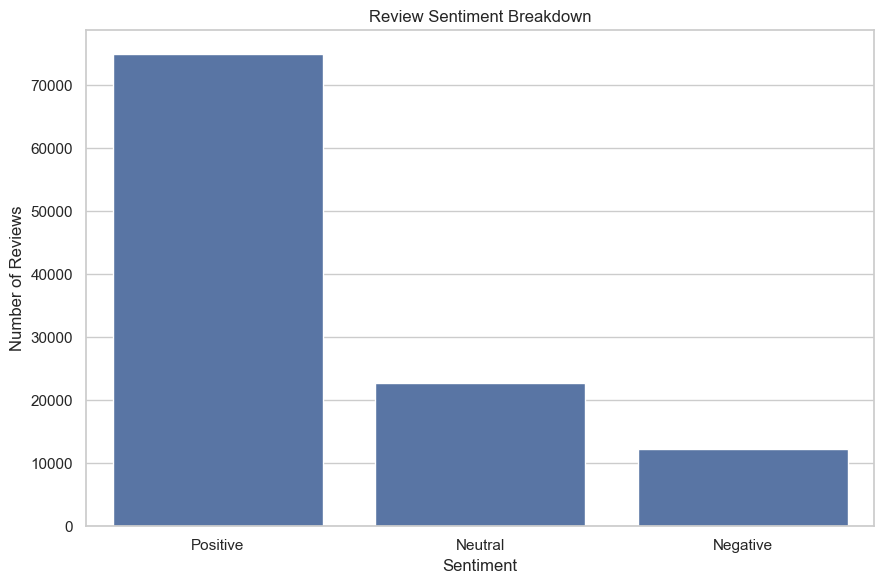

,sentiment,review_count
0,Positive,75007
1,Neutral,22759
2,Negative,12234


In [32]:
sentiment_order = ["Positive", "Neutral", "Negative"]

sentiment_counts = (
    reviews["sentiment"]
    .value_counts()
    .reindex(sentiment_order, fill_value=0)
    .rename_axis("sentiment")
    .reset_index(name="review_count")
)

fig, ax = plt.subplots(figsize=(9, 6))

sns.barplot(
    data=sentiment_counts,
    x="sentiment",
    y="review_count",
    order=sentiment_order,
    ax=ax
)

ax.set_title("Review Sentiment Breakdown")
ax.set_xlabel("Sentiment")
ax.set_ylabel("Number of Reviews")

plt.tight_layout()

plt.savefig(
    CHART_DIR / "10_Review_Sentiment_Breakdown.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(sentiment_counts)

**Observation:** Positive reviews dominated the dataset, with 75,007 reviews, representing approximately 68.19% of all reviews. Neutral reviews accounted for 22,759 (20.69%), while Negative reviews accounted for 12,234 (11.12%). The distribution indicates that recorded review sentiment is predominantly positive, although a smaller proportion of negative feedback remains important for understanding subscriber concerns.

## Phase 2 Summary — Exploratory Data Analysis

The exploratory data analysis examined subscriber demographics, viewing behaviour, content preferences, device usage, subscription plans, and review sentiment using the cleaned StreamFlix datasets. Ten visualisations were created to analyse monthly viewing activity, watch-hour trends, genre preferences, content-type distribution, country-wise viewing activity, subscriber plans, device usage, age distribution, genre completion rates, and review sentiment.

The analysis identified Drama as the leading genre by watch hours and TV Shows as the dominant content type by viewing time. The United States recorded the highest watch hours by subscriber country, Smart TVs were the most frequently used viewing devices, and the Standard plan had the largest subscriber base. Subscribers aged 35–44 generated the highest total watch hours, while positive reviews represented the majority of recorded review sentiment.

The time-series analysis also revealed a pronounced increase in viewing sessions and watch hours during the final months of the available timeline. This pattern should be validated before being interpreted as a confirmed increase in audience engagement. Overall, the analysis provides an initial understanding of subscriber behaviour and content consumption patterns and establishes a foundation for further KPI analysis and business recommendations.
